### Set up

In [1]:
!pip install python-dotenv


In [2]:
!pip install azure-cognitiveservices-vision-computervision

In [3]:
import requests
import os
import dotenv
# If you are using a Jupyter Notebook, uncomment the following line.
%matplotlib inline
import matplotlib.pyplot as plt
import json
from PIL import Image
from io import BytesIO

In [4]:
#!wget("https://upload.wikimedia.org/wikipedia/commons/thumb/1/12/Broadway_and_Times_Square_by_night.jpg/450px-Broadway_and_Times_Square_by_night.jpg")

In [5]:
# import os
from dotenv import load_dotenv

# Load .env file
load_dotenv()

# Read variables
azure_key = os.getenv("AZURE_VISION_KEY")
azure_endpoint = os.getenv("AZURE_VISION_ENDPOINT")

# print("KEY:", azure_key)
print("ENDPOINT:", azure_endpoint)

ENDPOINT: https://eastus.api.cognitive.microsoft.com/


In [6]:

analyze_url = f"{azure_endpoint}vision/v3.2/analyze"



print(analyze_url)

# Use the bundled image directly; Azure cannot fetch this external image URL.
query_image = os.path.join("..", "..", "images", "450px-Broadway_and_Times_Square_by_night.jpg")
if not os.path.isfile(query_image):
    query_image = os.path.join("..", query_image)
if not os.path.isfile(query_image):
    raise FileNotFoundError(f"Image file not found: {query_image}")



headers = {'Ocp-Apim-Subscription-Key': azure_key}
image_headers = {**headers, 'Content-Type': 'application/octet-stream'}
params = {'visualFeatures': 'Categories,Description,Color'}

with open(query_image, 'rb') as image_file:
    response = requests.post(analyze_url, headers=image_headers,
                             params=params, data=image_file)
response.raise_for_status()

# The 'analysis' object contains various fields that describe the image. The most
# relevant caption for the image is obtained from the 'description' property.
analysis = response.json()
print(json.dumps(response.json()))
image_caption = analysis["description"]["captions"][0]["text"].capitalize()
print(image_caption)


https://eastus.api.cognitive.microsoft.com/vision/v3.2/analyze
{"categories": [{"name": "outdoor_", "score": 0.00390625, "detail": {"landmarks": []}}, {"name": "outdoor_street", "score": 0.3984375, "detail": {"landmarks": []}}], "color": {"dominantColorForeground": "Brown", "dominantColorBackground": "Brown", "dominantColors": ["Brown"], "accentColor": "B54216", "isBwImg": false, "isBWImg": false}, "description": {"tags": ["building", "outdoor", "street", "city", "people", "busy", "night", "ride", "crowd"], "captions": [{"text": "a busy city street at night", "confidence": 0.5896901488304138}]}, "requestId": "95d0fc24-b0a0-4505-8af9-455565be633b", "metadata": {"height": 600, "width": 450, "format": "Jpeg"}, "modelVersion": "2021-05-01"}
A busy city street at night


In [7]:
print(json.dumps(response.json(), indent=4))

{
    "categories": [
        {
            "name": "outdoor_",
            "score": 0.00390625,
            "detail": {
                "landmarks": []
            }
        },
        {
            "name": "outdoor_street",
            "score": 0.3984375,
            "detail": {
                "landmarks": []
            }
        }
    ],
    "color": {
        "dominantColorForeground": "Brown",
        "dominantColorBackground": "Brown",
        "dominantColors": [
            "Brown"
        ],
        "accentColor": "B54216",
        "isBwImg": false,
        "isBWImg": false
    },
    "description": {
        "tags": [
            "building",
            "outdoor",
            "street",
            "city",
            "people",
            "busy",
            "night",
            "ride",
            "crowd"
        ],
        "captions": [
            {
                "text": "a busy city street at night",
                "confidence": 0.5896901488304138
            }
      

In [8]:
from azure.cognitiveservices.vision.computervision.models import VisualFeatureTypes

params = {'visualFeatures': [VisualFeatureTypes.tags]}
#params = {'visualFeatures': 'Description'}
with open(query_image, 'rb') as image_file:
    response = requests.post(analyze_url, headers=image_headers,
                             params=params, data=image_file)
response.raise_for_status()

# The 'analysis' object contains various fields that describe the image. The most
# relevant caption for the image is obtained from the 'description' property.
analysis = response.json()
print(json.dumps(response.json()))

print(json.dumps(response.json(), indent=4))

{"tags": [{"name": "building", "confidence": 0.9910045862197876}, {"name": "metropolis", "confidence": 0.9403555393218994}, {"name": "metropolitan area", "confidence": 0.9358731508255005}, {"name": "downtown", "confidence": 0.9340376853942871}, {"name": "outdoor", "confidence": 0.9233906269073486}, {"name": "skyscraper", "confidence": 0.9208872318267822}, {"name": "urban area", "confidence": 0.9175583124160767}, {"name": "street", "confidence": 0.8893557786941528}, {"name": "commercial building", "confidence": 0.8842802047729492}, {"name": "mixed-use", "confidence": 0.8771032094955444}, {"name": "crowded", "confidence": 0.8658456802368164}, {"name": "night", "confidence": 0.8426163196563721}, {"name": "city", "confidence": 0.8208400011062622}, {"name": "people", "confidence": 0.6946084499359131}, {"name": "light", "confidence": 0.6930656433105469}], "requestId": "f90c194d-17e7-4b0c-a1d7-beac69790939", "metadata": {"height": 600, "width": 450, "format": "Jpeg"}, "modelVersion": "2021-05

In [9]:
domain = "landmarks"
url = "https://images.pexels.com/photos/338515/pexels-photo-338515.jpeg"
language = "en"

params = {'analyze_image_by_domain': 'domain, url, language'}

data = {'url': url}
response = requests.post(analyze_url, headers=headers,
                         params=params, json=data)
response.raise_for_status()

# The 'analysis' object contains various fields that describe the image. The most
# relevant caption for the image is obtained from the 'description' property.
analysis = response.json()
print(json.dumps(response.json()))

print(json.dumps(response.json(), indent=4))
#print categories name
print(analysis['categories'][0]['name'])


{"categories": [{"name": "building_", "score": 0.9375}], "requestId": "dcbe2bfc-d513-4393-a859-3e2e3ee5b7dc", "metadata": {"height": 2000, "width": 3003, "format": "Jpeg"}, "modelVersion": "2021-05-01"}
{
    "categories": [
        {
            "name": "building_",
            "score": 0.9375
        }
    ],
    "requestId": "dcbe2bfc-d513-4393-a859-3e2e3ee5b7dc",
    "metadata": {
        "height": 2000,
        "width": 3003,
        "format": "Jpeg"
    },
    "modelVersion": "2021-05-01"
}
building_


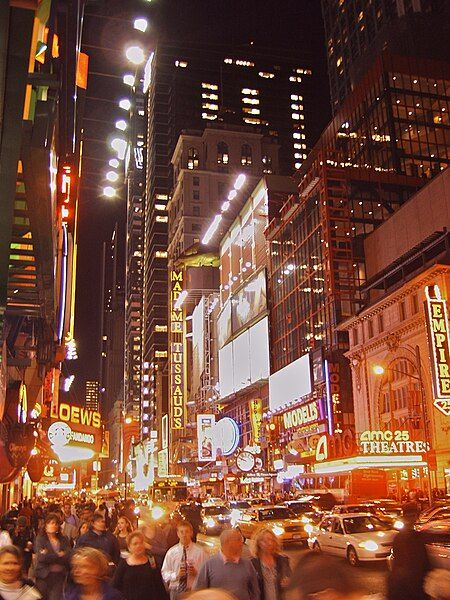

In [10]:
# Display the image and overlay it with the caption.
#image = Image.open(BytesIO(requests.get(image_url).content))
Image.open(query_image)

In [11]:
## analyze this image
if not os.path.isfile(query_image):
    raise FileNotFoundError(f"Image file not found: {query_image}")

new_image_params = {'visualFeatures': 'Categories,Description,Color'}
with open(query_image, 'rb') as image_file:
    new_image_response = requests.post(
        analyze_url,
        headers=image_headers,
        params=new_image_params,
        data=image_file,
    )
new_image_response.raise_for_status()

new_image_analysis = new_image_response.json()
print(json.dumps(new_image_analysis, indent=2))

captions = new_image_analysis.get('description', {}).get('captions', [])
if not captions:
    raise RuntimeError('Vision API returned no caption for this image.')
new_image_caption = captions[0]['text'].capitalize()
print(new_image_caption)


{
  "categories": [
    {
      "name": "outdoor_",
      "score": 0.00390625,
      "detail": {
        "landmarks": []
      }
    },
    {
      "name": "outdoor_street",
      "score": 0.3984375,
      "detail": {
        "landmarks": []
      }
    }
  ],
  "color": {
    "dominantColorForeground": "Brown",
    "dominantColorBackground": "Brown",
    "dominantColors": [
      "Brown"
    ],
    "accentColor": "B54216",
    "isBwImg": false,
    "isBWImg": false
  },
  "description": {
    "tags": [
      "building",
      "outdoor",
      "street",
      "city",
      "people",
      "busy",
      "night",
      "ride",
      "crowd"
    ],
    "captions": [
      {
        "text": "a busy city street at night",
        "confidence": 0.5896903872489929
      }
    ]
  },
  "requestId": "01749285-bec9-48d5-a811-d7f14d0873c5",
  "metadata": {
    "height": 600,
    "width": 450,
    "format": "Jpeg"
  },
  "modelVersion": "2021-05-01"
}
A busy city street at night


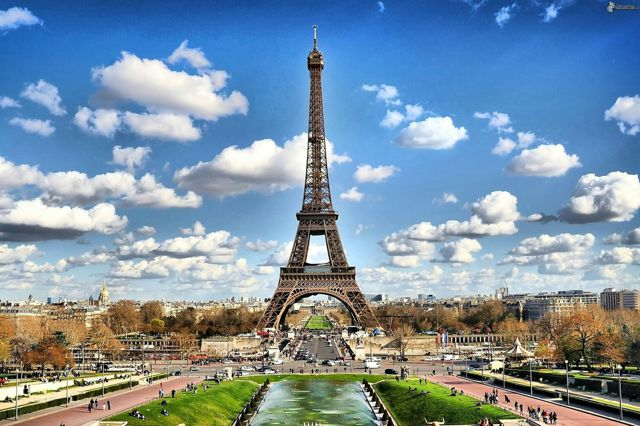

In [12]:
query_image = "../../images/pexels-photo-338515.jpeg"
Image.open(query_image)

In [13]:
## analyze this image


In [14]:
if not os.path.isfile(query_image):
    raise FileNotFoundError(f"Image file not found: {query_image}")

new_image_params = {'visualFeatures': 'Categories,Description,Color'}
with open(query_image, 'rb') as image_file:
    new_image_response = requests.post(
        analyze_url,
        headers=image_headers,
        params=new_image_params,
        data=image_file,
    )
new_image_response.raise_for_status()

new_image_analysis = new_image_response.json()
print(json.dumps(new_image_analysis, indent=2))

captions = new_image_analysis.get('description', {}).get('captions', [])
if not captions:
    raise RuntimeError('Vision API returned no caption for this image.')
new_image_caption = captions[0]['text'].capitalize()
print(new_image_caption)

{
  "categories": [
    {
      "name": "building_",
      "score": 0.93359375,
      "detail": {
        "landmarks": [
          {
            "name": "Eiffel Tower",
            "confidence": 0.971265435218811
          }
        ]
      }
    }
  ],
  "color": {
    "dominantColorForeground": "White",
    "dominantColorBackground": "Blue",
    "dominantColors": [
      "Blue",
      "White"
    ],
    "accentColor": "1E4E91",
    "isBwImg": false,
    "isBWImg": false
  },
  "description": {
    "tags": [
      "sky",
      "outdoor",
      "city",
      "day"
    ],
    "captions": [
      {
        "text": "a tall metal tower with Eiffel Tower in the background",
        "confidence": 0.4051917493343353
      }
    ]
  },
  "requestId": "69c77244-45ad-4183-bc7c-a84462f5bdc7",
  "metadata": {
    "height": 2000,
    "width": 3003,
    "format": "Jpeg"
  },
  "modelVersion": "2021-05-01"
}
A tall metal tower with eiffel tower in the background
